# Training Deep Neural Networks

Chapter 11 instructor walkthrough. A neural network can become very good at the examples it practices on and still make mistakes on new examples. In this lesson we train a flower classifier and learn how to tell whether more training is actually helping. The main goal is to make sensible training decisions and explain the evidence for them.

We use the small iris dataset so we can focus on the training process. This is a modest network with two hidden layers, not a demonstration that iris classification needs a very deep network.

## Step 1: Reserve the test set and explore the training rows

We will put 30 flowers aside for the final test. Of the remaining flowers, 90 will teach the network and 30 will help us judge it while we work.

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv('iris_demo.csv')
train_all, test = train_test_split(
    df, test_size=.2, stratify=df.species, random_state=42
)
train, val = train_test_split(
    train_all, test_size=.25, stratify=train_all.species, random_state=42
)
print(len(train), len(val), len(test))
print(train.isna().sum(), train.species.value_counts())

90 30 30
sepal_length_cm    0
sepal_width_cm     0
petal_length_cm    0
petal_width_cm     0
species            0
dtype: int64 species
virginica     30
setosa        30
versicolor    30
Name: count, dtype: int64


The first split reserves 20% of 150 rows, or 30 rows, for testing. The second split takes 25% of the remaining 120 rows, or 30 rows, for validation. stratify keeps the species proportions in each split. random_state makes the split repeatable.

Baseline: a classifier that always guesses one species would be right on one third of these balanced rows. Record 33.3% as the simple accuracy baseline. Beating it tells us the model learned more than that constant guess; it does not by itself show that a neural network is the best model for this data.

## Step 2: Put the measurements into a form PyTorch can use

Each input has four measurements. The model needs numbers for the answers too, so we will give each species an integer ID. The CSV places its species column last.

In [2]:
import torch
from sklearn.preprocessing import StandardScaler
features = list(df.columns[:-1])
classes = sorted(train.species.unique())
scaler = StandardScaler().fit(train[features])
def tensors(frame):
    X = torch.tensor(scaler.transform(frame[features]), dtype=torch.float32)
    y = torch.tensor([classes.index(s) for s in frame.species], dtype=torch.long)
    return (X, y)
X_train, y_train = tensors(train)
X_val, y_val = tensors(val)
print(X_train.shape, X_val.shape, y_train.shape, y_train.dtype)

torch.Size([90, 4]) torch.Size([30, 4]) torch.Size([90]) torch.int64


StandardScaler learns a mean and a standard deviation for each measurement from the training rows only. Using held-out rows to estimate the transformation would let information from those rows enter development. features contains the four measurement column names. classes is an alphabetically sorted list of the three species names, and that list defines which species IDs 0, 1, and 2 mean.

Check: X_train.shape should be [90, 4], X_val.shape [30, 4], y_train.shape [90], and y_train.dtype torch.int64. A feature row contains four inputs. A target contains one class ID.

## Step 3: Build a network with room to overfit

This network has more capacity than this small dataset needs. That gives us a reason to watch validation performance carefully. It may still perform well, so we will measure rather than promise an overfitting curve.

In [3]:
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

def make_model(dropout=0.0):
    torch.manual_seed(42)
    return nn.Sequential(
        nn.Linear(4, 64),
        nn.ReLU(),
        nn.Dropout(dropout),
        nn.Linear(64, 64),
        nn.ReLU(),
        nn.Linear(64, 3)
    )

loader = DataLoader(
    TensorDataset(X_train, y_train), batch_size=16, shuffle=True
)
loss_fn = nn.CrossEntropyLoss()

nn.Sequential passes the output of each layer to the next. The first Linear layer takes four measurements and produces 64 hidden values. ReLU keeps positive values and replaces negative values with zero. Dropout acts on those hidden activations. The next Linear layer produces another 64 values, and the final layer produces three scores called logits, one per species.

Note: 64 does not mean there are 64 flower species. These are hidden values the model learns to use. Only the final three outputs correspond to species.

We pass logits directly to CrossEntropyLoss. Do not add a softmax layer here: this loss already handles the needed calculation. Later, argmax chooses the position of the largest score, which gives the predicted class ID.

## Step 4: Set up training and the saved checkpoint

Train with dropout and weight decay, while tracking how well the model handles validation rows. model uses dropout=0.2. opt uses Adam with a learning rate of 0.01 and weight_decay=0.001. patience=15 means we allow 15 consecutive epochs without a sufficient validation improvement. The comparison best - 1e-4 requires a decrease greater than 0.0001, so an extremely tiny change will not reset the counter.

After each epoch, we check both sets with dropout turned off. The validation loss will decide whether this epoch deserves a saved copy. detach().clone() makes an independent copy of each saved tensor. Without a real copy, later updates could change the weights we meant to preserve.

In [4]:
model = make_model(dropout=0.2)
opt = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=0.001)
history = []
best = float('inf')
best_state = None
patience = 15
wait = 0
for epoch in range(150):
    model.train()
    for xb, yb in loader:
        opt.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        opt.step()
    model.eval()
    with torch.inference_mode():
        train_loss = loss_fn(model(X_train), y_train).item()
        val_loss = loss_fn(model(X_val), y_val).item()
    history.append((train_loss, val_loss))
    if val_loss < best - 0.0001:
        best = val_loss
        best_state = {
            k: v.detach().clone()
            for k, v in model.state_dict().items()
        }
        wait = 0
    else:
        wait += 1
    if wait >= patience:
        break
model.load_state_dict(best_state)
print('epochs:', len(history), 'best validation loss:', round(best, 3))

epochs: 79 best validation loss: 0.154


A meaningful validation improvement saves a fresh checkpoint and resets wait. Otherwise wait increases. The loop ends at the patience limit or at 150 epochs. load_state_dict restores the saved weights, even if the loop ran several worse epochs afterward.

## Step 5: Read the curves and calculate validation accuracy

Each point represents a recorded epoch. If both curves generally fall, the model is improving on both sets. If training loss falls while validation loss rises for a sustained period, that is evidence of overfitting. Validation curves can be noisy because there are only 30 validation flowers. One spike is weaker evidence than a sustained pattern.

The plot shows every recorded epoch, including any epochs after the best checkpoint. The printed accuracy describes the restored checkpoint, so it need not describe the last point on the curve.

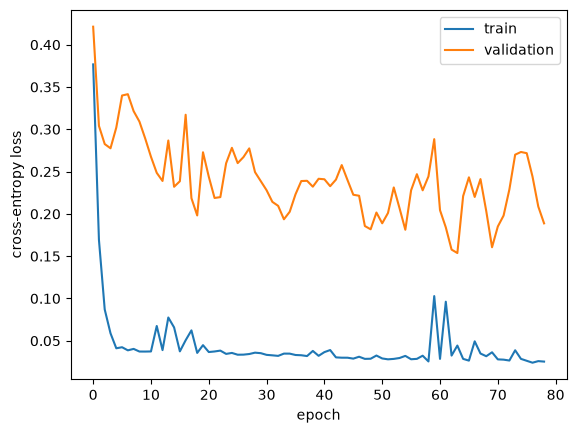

validation accuracy: 0.9333333373069763


In [5]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
ax.plot([h[0] for h in history], label='train')
ax.plot([h[1] for h in history], label='validation')
ax.set(xlabel='epoch', ylabel='cross-entropy loss')
ax.legend()
plt.show()
model.eval()
with torch.inference_mode():
    val_pred = model(X_val).argmax(1)
print('validation accuracy:', (val_pred == y_val).float().mean().item())

## Controlled comparison: the same training run with dropout removed

Now we have a concrete question to investigate: does removing dropout help or hurt validation performance in this run? Procedure: duplicate the Step 4 and Step 5 cells. In the duplicate training cell, change only dropout=0.2 in the make_model call to dropout=0.0. Keep the split, scaler, architecture, optimizer, batch size, epoch limit, and stopping rule the same. The second run uses its own history and best variables so both runs stay recorded. Both runs still use weight decay and early stopping. This experiment isolates the dropout setting; it does not compare all safeguards against no safeguards.

In [6]:
model2 = make_model(dropout=0.0)
opt2 = torch.optim.Adam(model2.parameters(), lr=0.01, weight_decay=0.001)
history2 = []
best2 = float('inf')
best_state2 = None
patience = 15
wait = 0
for epoch in range(150):
    model2.train()
    for xb, yb in loader:
        opt2.zero_grad()
        loss = loss_fn(model2(xb), yb)
        loss.backward()
        opt2.step()
    model2.eval()
    with torch.inference_mode():
        train_loss = loss_fn(model2(X_train), y_train).item()
        val_loss = loss_fn(model2(X_val), y_val).item()
    history2.append((train_loss, val_loss))
    if val_loss < best2 - 0.0001:
        best2 = val_loss
        best_state2 = {
            k: v.detach().clone()
            for k, v in model2.state_dict().items()
        }
        wait = 0
    else:
        wait += 1
    if wait >= patience:
        break
model2.load_state_dict(best_state2)
print('epochs:', len(history2), 'best validation loss:', round(best2, 3))

epochs: 26 best validation loss: 0.215


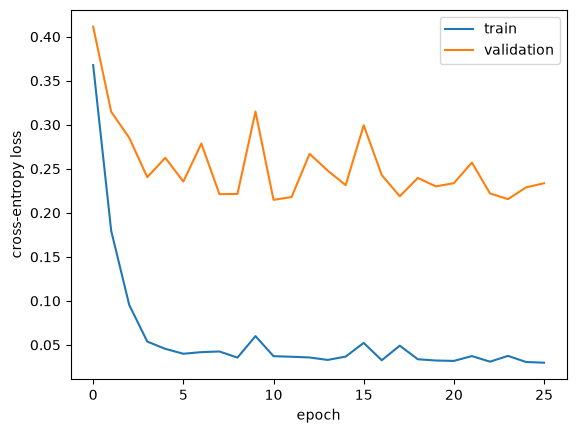

validation accuracy: 0.9333333373069763


In [7]:
fig, ax = plt.subplots()
ax.plot([h[0] for h in history2], label='train')
ax.plot([h[1] for h in history2], label='validation')
ax.set(xlabel='epoch', ylabel='cross-entropy loss')
ax.legend()
plt.show()
model2.eval()
with torch.inference_mode():
    val_pred2 = model2(X_val).argmax(1)
print('validation accuracy:', (val_pred2 == y_val).float().mean().item())

## Choose the model while the test set is still untouched

Comparison results:
- Dropout 0.2: 79 epochs, best validation loss 0.154, validation accuracy 0.9333 (28 of 30 correct)
- Dropout 0.0: 26 epochs, best validation loss 0.215, validation accuracy 0.9333 (28 of 30 correct)

We chose dropout 0.2 because its best validation loss is lower, 0.154 against 0.215. The validation accuracies tie at 0.9333, so the evidence is modest: dropout wins on loss but not on accuracy. We did not use test accuracy as a tiebreaker, and the test set is still untouched.

The dropout 0.2 model is still stored in `model` with its restored best weights, and the Step 5 cell already left it in evaluation mode. We confirm evaluation mode again before the final test.

## Step 6: Make the final test prediction and explain it

Our choices are now fixed. This result tells us how the chosen model handled the held-out flowers. We will report it, including any disappointing outcome.

In [8]:
model.eval()
X_test, y_test = tensors(test)
with torch.inference_mode():
    test_pred = model(X_test).argmax(1)
print('final test accuracy:', (test_pred == y_test).float().mean().item())

final test accuracy: 0.9666666388511658


## Exit ticket

**What evidence supported our choice?** The dropout 0.2 run reached a best validation loss of 0.154, lower than the dropout 0.0 run at 0.215. Both runs scored 0.9333 validation accuracy, so the loss gap is the deciding evidence, and it is modest since accuracy tied.

**What does early stopping restore?** Early stopping keeps a copy of the weights whenever validation loss improves by more than 0.0001, stops after 15 epochs without such an improvement, and then restores the best saved weights. The last epoch and the best epoch may be different: the dropout 0.2 run trained for 79 epochs, but its reported accuracy describes the restored checkpoint, not necessarily the final epoch.

**What would we investigate next, and how would we keep it separate from the final test?** We would repeat the dropout comparison with several different seeds, since this comparison is only one run per setting and results can differ across runs. We would keep that experiment separate from the final test by making all new choices on validation results only, and by using a fresh held-out evaluation plan for any further test claim rather than reusing these same 30 test rows as feedback.